# Loading Dataset 

In [1]:
import kagglehub

import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from tqdm import tqdm
import torch

import matplotlib.pyplot as plt 

/home/vansh/.venvs/core/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
dataset_path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print(f"Dataset Path: {dataset_path}")

Dataset Path: /home/vansh/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2


In [3]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),       # Resize images to a standard size
    transforms.ToTensor(),                # Convert images to PyTorch Tensors
    # transforms.Normalize(                 # Normalize with ImageNet standards
    #     mean=[0.485, 0.456, 0.406], 
    #     std=[0.229, 0.224, 0.225]
    # )
])

dataset = ImageFolder(root=dataset_path, transform=transform)
print("Number of datapoints", len(dataset))

Number of datapoints 11712


Image shape: torch.Size([3, 224, 224])
Label: 0


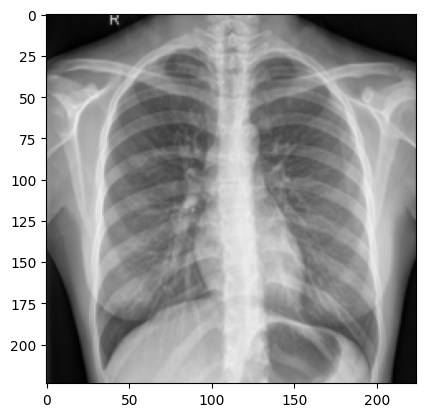

In [4]:
sample = dataset[10]
image = sample[0]
print("Image shape:", image.shape)
plt.imshow(image.permute(1,2,0))
print(f"Label: {sample[1]}")

# Model Training

In [5]:
BATCH_SIZE = 8
EPOCHS = 50
LR = 0.0001
BETA = 1.0
DEVICE = "cuda"
LATENT_DIM = 128

In [ ]:
from model.VAE import VAE

vae = VAE(latent_dim=LATENT_DIM, device=DEVICE)
data_loader = DataLoader(dataset=dataset, batch_size=BATCH_SIZE, shuffle=True)    
optimizer = torch.optim.Adam(vae.parameters(), lr = LR)


In [ ]:
import os
import wandb

wandb.init(project="ECE285_HW1_VAE", config={
    "learning_rate": LR,
    "batch_size": BATCH_SIZE,
    "beta": BETA,
    "epochs": EPOCHS,
    "latent_dim": LATENT_DIM,
})


def train():
    os.makedirs("checkpoints", exist_ok=True)

    for epoch in range(EPOCHS):
        print(f"Epoch {epoch}:")
        for batch_idx, (images, _) in enumerate(tqdm(data_loader)):
            images = images.to(device=DEVICE)
            recon, mean, log_var = vae(images)
            optimizer.zero_grad()
            recon_loss, kl = vae.compute_loss(recon=recon, target=images, mean=mean, log_var=log_var)
            loss = recon_loss + BETA * kl
            loss.backward()
            optimizer.step()

            global_step = epoch * len(data_loader) + batch_idx
            wandb.log({
                "loss/kl": kl.item(),
                "loss/reconstruction": recon_loss.item(),
                "loss/total": loss.item(),
                "train/epoch": epoch,
            }, step=global_step)

        if (epoch + 1) % 5 == 0:
            checkpoint_path = f"checkpoints/vae_epoch_{epoch + 1}.pt"
            torch.save({
                "epoch": epoch + 1,
                "model_state_dict": vae.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "loss": loss.item(),
            }, checkpoint_path)

            artifact = wandb.Artifact(
                name=f"vae-model-epoch-{epoch + 1}",
                type="model",
                description=f"VAE checkpoint after epoch {epoch + 1}",
            )
            artifact.add_file(checkpoint_path)
            wandb.log_artifact(artifact)

    wandb.finish()


train()


Epoch 0:


  0%|          | 0/1464 [00:00<?, ?it/s][W1018 03:44:53.003007077 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 788529152 bytes (free: 456458240, total: 8082096128).
[W1018 03:44:53.013123040 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 788529152 bytes (free: 550830080, total: 8082096128).
  0%|          | 0/1464 [00:00<?, ?it/s]


OutOfMemoryError: CUDA out of memory. Tried to allocate 752.00 MiB. GPU 0 has a total capacity of 7.53 GiB of which 525.31 MiB is free. Including non-PyTorch memory, this process has 6.99 GiB memory in use. Of the allocated memory 6.69 GiB is allocated by PyTorch, and 42.42 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)